In [1]:
import numpy as np
import matplotlib.pyplot as plt
from utils import PACBayesCurve
from data.ibl.utils import load_behavior_data, load_cohort, block_average
from data.ibl.kl import PolicyKL, KLResult
from scipy.stats import pearsonr, spearmanr
from data.ibl.wheel import collect_trials, TrialSet

In [2]:
# figure formatting (as in the original notebooks)
import seaborn as sns
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params)

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['figure.dpi'] = 100

# Basic prediction of the theory: scaling law, effective dimensionality

## Section 1: PAC-Bayes Learning Curve
Aggregate learning-curve analysis on the full CSV cohort (140 mice, 7 labs): the per-lab
average fit, the spread of individual $\alpha$ / $\phi$, and how learning speed relates to them.

In [3]:
all_data, uuid, col_names = load_behavior_data()
labs = list(all_data.keys())
all_sub = [all_data[lab][s] for lab in labs for s in all_data[lab]]
print(f'{len(all_sub)} subjects across {len(labs)} labs')

140 subjects across 7 labs


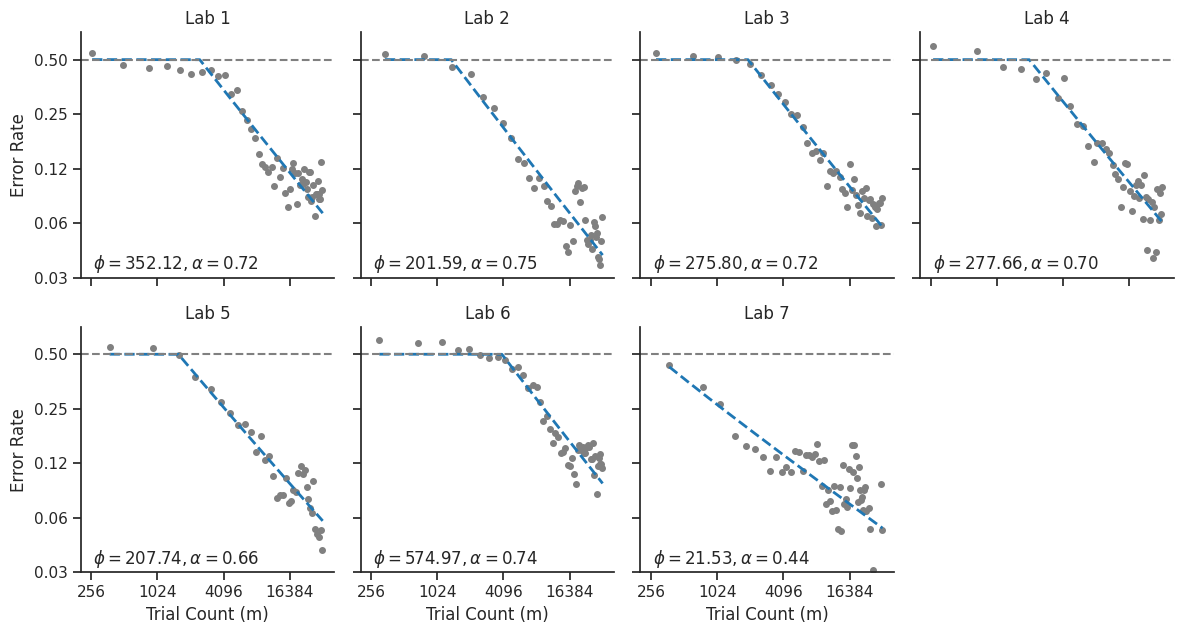

In [4]:
# per-lab average learning curves (power-law / PAC-Bayes fit)
fig, axs = plt.subplots(2, 4, figsize=(12, 6.5), sharex=True, sharey=True)
axs = axs.flatten()

for i, lab in enumerate(labs):
    ax = axs[i]
    sub_data_list = [all_data[lab][sub] for sub in all_data[lab].keys()]
    n_trials, p_correct = block_average(sub_data_list)

    cutoff = 32768  # 2**15
    m_trials = np.cumsum(n_trials)
    m_trials = m_trials[m_trials <= cutoff]
    p_correct = p_correct[:len(m_trials)]

    # error rate vs trial count in log-log space
    ax.plot(np.log2(m_trials), np.log2(1 - p_correct), 'o', markersize=4, color='grey')
    ax.set_ylim([-5, -0.5])
    x_ticks = [8, 10, 12, 14]
    ax.set_xticks(x_ticks); ax.set_xticklabels([int(2 ** x) for x in x_ticks])
    y_ticks = np.arange(-5, 0, 1)
    ax.set_yticks(y_ticks); ax.set_yticklabels(['%.2f' % (2 ** float(y)) for y in y_ticks])

    # fit power-law and PAC-Bayes; show the PAC-Bayes fit    
    pb = PACBayesCurve(cap=0.5).fit(m_trials, 1 - p_correct)     # g(m) = (2/3) phi/m + (2 phi/m) ** alpha
    m_range = np.arange(np.min(m_trials), cutoff + 1)
    ax.plot(np.log2(m_range), np.log2(pb.predict(m_range)), '--', color='tab:blue', linewidth=2)
    ax.text(0.05, 0.1, r'$\phi=%.2f, \alpha=%.2f$' % (pb.params['phi'], pb.params['alpha']),
            transform=ax.transAxes, verticalalignment='top')

    ax.set_title(lab); ax.set_xlabel('Trial Count (m)'); ax.set_ylabel('Error Rate')
    ax.axhline(y=-1, color='gray', linestyle='--'); ax.label_outer()

axs.flat[-1].set_axis_off()
# plt.savefig('./per_lab_curves.pdf', bbox_inches='tight', dpi=300)
plt.tight_layout(); plt.show()

In [5]:
# individual-mouse PAC-Bayes fits + trials-to-criterion (all labs)
alphas, phis, r2, m_thr = [], [], [], []
for lab in labs:
    for sid, arr in all_data[lab].items():
        m = np.cumsum(arr[:, 1])                           # cumulative trials
        pb = PACBayesCurve(cap=0.5).fit(m, 1 - arr[:, 3])  # fit easy-trial error (col 3)
        alphas.append(pb.params['alpha'])
        phis.append(pb.params['phi'])
        r2.append(pb.params['r2'])
        hit = np.flatnonzero(arr[:, 3] >= 0.84)            # trials to 84% easy performance
        m_thr.append(m[hit[0]] if len(hit) else np.inf)

alphas, phis, r2, m_thr = map(np.array, (alphas, phis, r2, m_thr))

R2_MIN = 0.25
keep = r2 >= R2_MIN
print(f'{len(alphas)} mice | {keep.sum()} with fit R^2 >= {R2_MIN}')

140 mice | 128 with fit R^2 >= 0.25


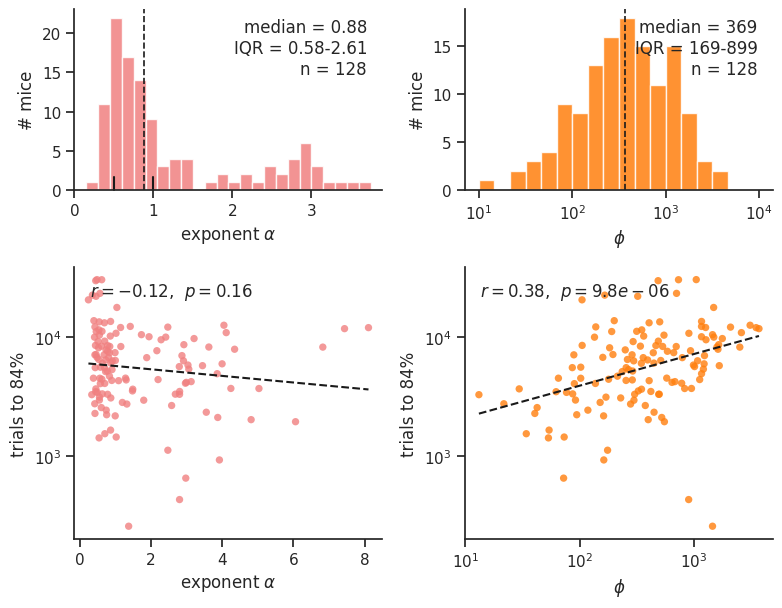

In [8]:
# figure: individual alpha / phi estimates and how each relates to learning speed
mpl.rcParams['pdf.fonttype'] = 42   # TrueType: text stays editable in Illustrator

C_ALPHA = 'lightcoral'
C_PHI = 'tab:orange'

# all mice from Section 1 with R^2 >= R2_MIN that reached the 84% criterion
sel = keep & np.isfinite(m_thr)
log_phi = np.log10(phis[sel])

fig, axs = plt.subplots(2, 2, figsize=(8, 6.25),
                        gridspec_kw=dict(height_ratios=[2, 3]))   # shorter histogram row

# top left: distribution of alpha
ax = axs[0, 0]
ax.hist(alphas[sel], bins=np.arange(0, 3.9, 0.15), color=C_ALPHA, alpha=0.85, edgecolor='white')
q25, q50, q75 = np.percentile(alphas[sel], [25, 50, 75])
ax.axvline(q50, color='k', lw=1.2, ls='--')
for x_mark in (0.5, 1.0):        # exponent range predicted by the theory
    ax.plot([x_mark, x_mark], [0, 0.07], transform=ax.get_xaxis_transform(),
            color='k', lw=1.5, clip_on=False)
ax.set_xlim([0, 3.9])
ax.set_xlabel(r'exponent $\alpha$'); ax.set_ylabel('# mice')
ax.text(0.95, 0.95, 'median = %.2f\nIQR = %.2f-%.2f\nn = %d' % (q50, q25, q75, sel.sum()),
        transform=ax.transAxes, va='top', ha='right')

# top right: distribution of phi (log scale)
ax = axs[0, 1]
lo, hi = np.floor(log_phi.min()), np.ceil(log_phi.max())
ax.hist(log_phi, bins=np.linspace(lo, hi, int((hi - lo) * 6) + 1), color=C_PHI,
        alpha=0.85, edgecolor='white')
q25, q50, q75 = np.percentile(log_phi, [25, 50, 75])
ax.axvline(q50, color='k', lw=1.2, ls='--') 
ticks = np.arange(int(lo), int(hi) + 1)
ax.set_xticks(ticks); ax.set_xticklabels([r'$10^{%d}$' % t for t in ticks])
ax.set_xlabel(r'$\phi$'); ax.set_ylabel('# mice')
ax.text(0.95, 0.95, 'median = %.0f\nIQR = %.0f-%.0f\nn = %d'
        % (10 ** q50, 10 ** q25, 10 ** q75, sel.sum()),
        transform=ax.transAxes, va='top', ha='right')

# bottom left: alpha vs learning speed
ax = axs[1, 0]
r_val, pval = pearsonr(alphas[sel], np.log10(m_thr[sel]))      # alpha vs log trials
ax.scatter(alphas[sel], m_thr[sel], s=28, color=C_ALPHA, alpha=0.8, edgecolors='none')
slope, intercept = np.polyfit(alphas[sel], np.log10(m_thr[sel]), 1)
x_line = np.linspace(alphas[sel].min(), alphas[sel].max(), 100)
ax.plot(x_line, 10 ** (intercept + slope * x_line), '--', color='k', lw=1.5)
ax.set_yscale('log')
ax.minorticks_off()
ax.set_xlabel(r'exponent $\alpha$'); ax.set_ylabel('trials to 84%')
ax.text(0.05, 0.95, r'$r = %.2f$,  $p = %.2g$' % (r_val, pval),
        transform=ax.transAxes, va='top')

# bottom right: phi vs learning speed
ax = axs[1, 1]
r_val, pval = pearsonr(np.log10(phis[sel]), np.log10(m_thr[sel]))   # log phi vs log trials
ax.scatter(phis[sel], m_thr[sel], s=28, color=C_PHI, alpha=0.8, edgecolors='none')
slope, intercept = np.polyfit(np.log10(phis[sel]), np.log10(m_thr[sel]), 1)
x_line = np.linspace(np.log10(phis[sel]).min(), np.log10(phis[sel]).max(), 100)
ax.plot(10 ** x_line, 10 ** (intercept + slope * x_line), '--', color='k', lw=1.5)
ax.set_xscale('log'); ax.set_yscale('log')
ax.minorticks_off()
ax.set_xlabel(r'$\phi$'); ax.set_ylabel('trials to 84%')
ax.text(0.05, 0.95, r'$r = %.2f$,  $p = %.2g$' % (r_val, pval),
        transform=ax.transAxes, va='top')

plt.tight_layout()
fig.savefig('ibl_alpha_phi.pdf', dpi=300, bbox_inches='tight')   # vector, for Illustrator
plt.show()

## Secion 2: Rescaling the trial axis: $(m/d)^{\alpha}$

In [9]:
# --- 1. fit the single-component power law to each mouse ---
# g(m) = (d/m)**alpha, capped at chance (0.5), asymptote fixed at zero error.
# d is a trials-to-scale and alpha the exponent, so in log-log each mouse is a straight line.
from utils import PowerLawCurve

sessions = [(np.cumsum(arr[:, 1]), 1 - arr[:, 3], arr[:, 1])      # cumulative trials, error, weights
            for lab in labs for arr in all_data[lab].values()]

pl_d, pl_alpha, pl_r2 = [], [], []
for m, err, _ in sessions:
    pl = PowerLawCurve(cap=0.5).fit(m, err)
    pl_d.append(pl.params['d']); pl_alpha.append(pl.params['alpha']); pl_r2.append(pl.params['r2'])
pl_d, pl_alpha, pl_r2 = map(np.array, (pl_d, pl_alpha, pl_r2))

print('fitted %d mice | median R^2 %.2f, alpha %.2f, d %.0f'
      % (len(sessions), np.median(pl_r2), np.median(pl_alpha), np.median(pl_d)))

fitted 140 mice | median R^2 0.71, alpha 0.87, d 840


In [10]:
# --- 2. pick which mice to show ---
# every mouse whose power-law fit is good enough and whose d is not implausibly small,
# ordered by d so the colours run with speed
R2_SHOW = 0.25
D_MIN = 250

good = np.flatnonzero((pl_r2 >= R2_SHOW) & (pl_d > D_MIN))
show = good[np.argsort(pl_d[good])]

# colour by d itself, so colour reads as a learning-speed scale
from matplotlib.colors import LogNorm
cmap = plt.get_cmap('viridis')
norm = LogNorm(vmin=pl_d[show].min(), vmax=pl_d[show].max())
colors = [cmap(norm(pl_d[i])) for i in show]

print('showing %d of %d mice with R^2 >= %.2f and d > %g' % (len(show), len(pl_r2), R2_SHOW, D_MIN))
print('  R^2 %.2f-%.2f, alpha %.2f-%.2f, d %.0f-%.0f'
      % (pl_r2[show].min(), pl_r2[show].max(), pl_alpha[show].min(),
         pl_alpha[show].max(), pl_d[show].min(), pl_d[show].max()))

showing 112 of 140 mice with R^2 >= 0.25 and d > 250
  R^2 0.27-0.99, alpha 0.27-10.47, d 252-5841


In [11]:
# --- 3. bin each mouse's sessions in log trial count ---
# later bins pool more trials, so the noise in log space stays roughly constant instead of
# exploding as the error rate approaches zero; within a bin, error is averaged over trials
N_BINS = 12

binned = []
for i in show:
    m, err, w = sessions[i]
    bin_edges = np.logspace(np.log10(m.min()), np.log10(m.max()), N_BINS + 1)
    idx = np.clip(np.digitize(m, bin_edges) - 1, 0, N_BINS - 1)
    bx, by = [], []
    for b in range(N_BINS):
        s = idx == b
        if s.any():
            bx.append(np.average(m[s], weights=w[s]))
            by.append(np.average(err[s], weights=w[s]))
    binned.append((np.array(bx), np.array(by)))

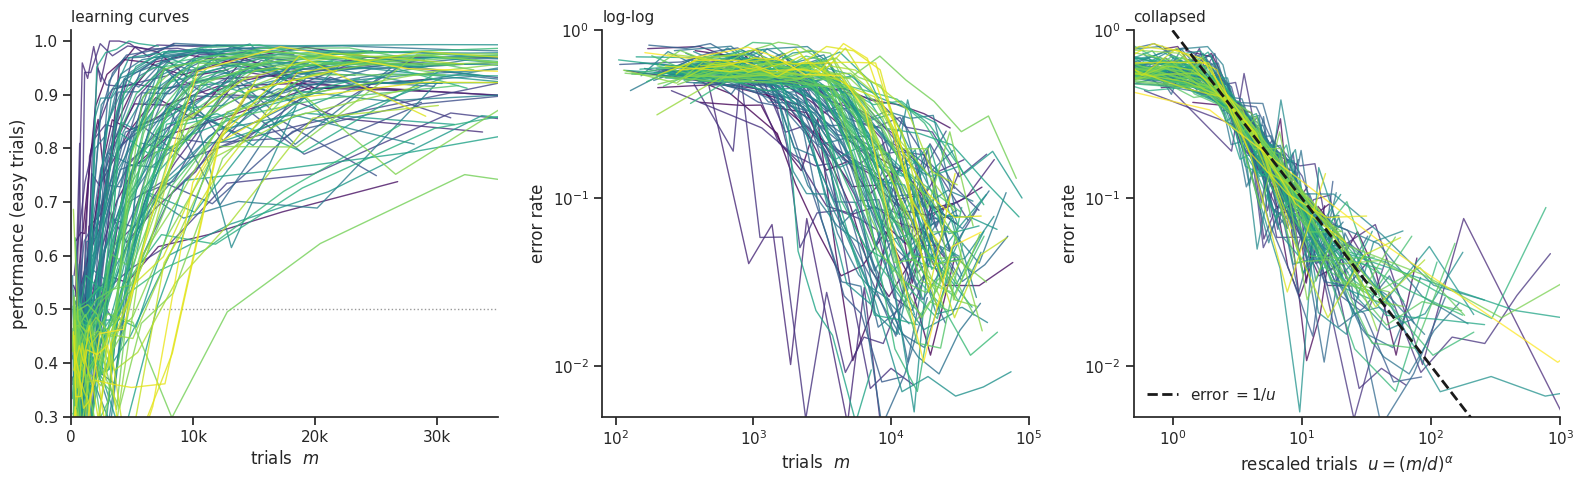

In [13]:
# set 1: the data as usually plotted, then log-log, then collapsed
fig, axs = plt.subplots(1, 3, figsize=(16, 5))

# left: performance vs trials, the usual IBL view (linear axes)
ax = axs[0]
for (bx, by), c in zip(binned, colors):
    ax.plot(bx, 1 - by, '-', color=c, lw=1.0, alpha=0.8, solid_capstyle='round')
ax.axhline(0.5, color='0.6', lw=1, ls=':', zorder=0)              # chance
ax.set(xlabel='trials  $m$', ylabel='performance (easy trials)',
       xlim=[0, 3.5e4], ylim=[0.3, 1.02])
ax.set_xticks([0, 1e4, 2e4, 3e4]); ax.set_xticklabels(['0', '10k', '20k', '30k'])
ax.set_title('learning curves', loc='left', fontsize=11)

# middle: the same curves, log-log and log-binned
ax = axs[1]
for (bx, by), c in zip(binned, colors):
    ok = by > 0
    ax.plot(bx[ok], by[ok], '-', color=c, lw=1.0, alpha=0.8, solid_capstyle='round')
ax.set(xscale='log', yscale='log', xlabel='trials  $m$', ylabel='error rate',
       xlim=[8e1, 1e5], ylim=[5e-3, 1])
ax.minorticks_off()
ax.set_title('log-log', loc='left', fontsize=11)

# right: trials rescaled by each mouse's own fit
ax = axs[2]
u_ref = np.logspace(0, 3, 200)
ax.plot(u_ref, 1 / u_ref, '--', color='k', lw=2, zorder=5,        # error = 1/u : slope -1
        label=r'error $= 1/u$')
for (bx, by), i, c in zip(binned, show, colors):
    ok = by > 0
    ax.plot((bx[ok] / pl_d[i]) ** pl_alpha[i], by[ok], '-', color=c, lw=1.0, alpha=0.75,
            solid_capstyle='round')
ax.set(xscale='log', yscale='log', xlabel=r'rescaled trials  $u = (m/d)^{\alpha}$',
       ylabel='error rate', xlim=[0.5, 1e3], ylim=[5e-3, 1])
ax.minorticks_off()
ax.set_title('collapsed', loc='left', fontsize=11)
ax.legend(frameon=False, loc='lower left')

plt.tight_layout()
fig.savefig('collapse.pdf', dpi=300, bbox_inches='tight')
plt.show()